Проведём исследование на примере данных с Титаника

In [96]:
#----------------Импорт данных--------------------

import pandas as pd


path_gender_submission = 'D:/MIREA/DPO/Learning/Practic1_7/gender_submission.csv'
path_test = 'D:/MIREA/DPO/Learning/Practic1_7/test.csv'
path_train = 'D:/MIREA/DPO/Learning/Practic1_7/train.csv'

df_gender = pd.read_csv(path_gender_submission)
df_train = pd.read_csv(path_train)
df_test = pd.read_csv(path_test)

df_train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [97]:
print('Shape gender: ({0}, {1})'.format(*df_gender.shape))
print('Shape train: ({0}, {1})'.format(*df_train.shape))
print('Shape test: ({0}, {1})'.format(*df_test.shape))

Shape gender: (418, 2)
Shape train: (891, 12)
Shape test: (418, 11)


In [98]:
df_train.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [99]:
df_train.describe(include='all')

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Dooley, Mr. Patrick",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


In [100]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


[]

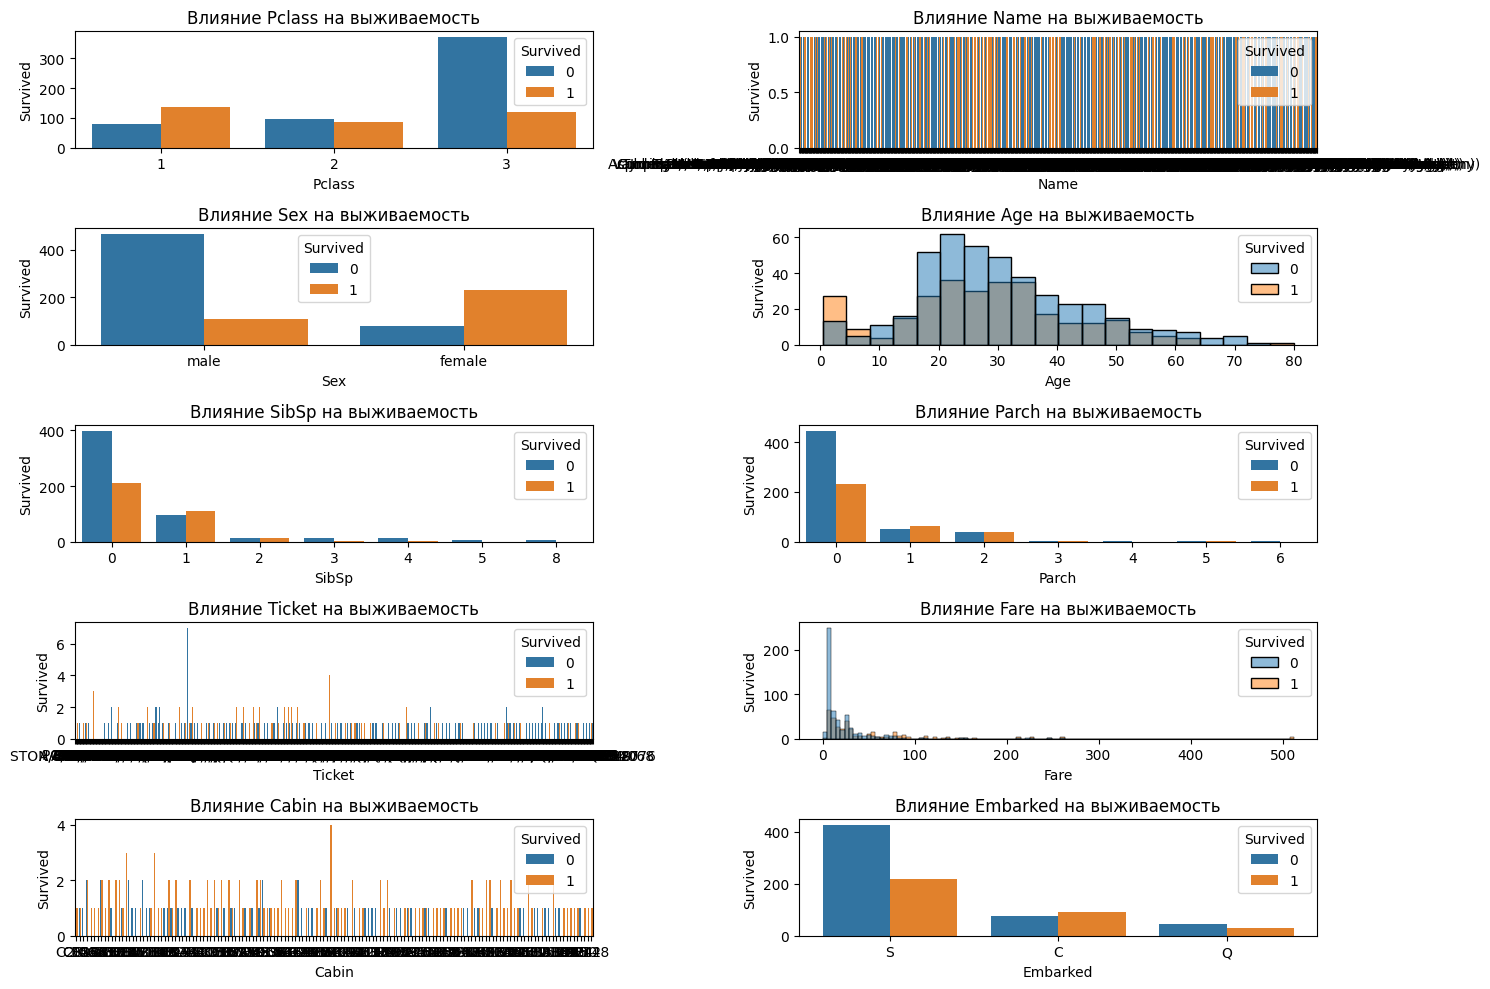

In [101]:
# Хорошо, значит проверять будем по id пассажира
# Выведем различные закономерности между данным параметров и выживаемостью
# Очевидно, пока трогать имена не будем, понятно, что возможно, что именно семьи отпускали
# но это потом, затрансформируем данные

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


fig, ax = plt.subplots(nrows=5, ncols=2, figsize=(15, 10))
col_to_check = df_train.columns[2:]

ax_flat = ax.flatten()

fig.set_label('Анализ зависимостей')
for i, ax in enumerate(ax_flat):
    col = col_to_check[i]
    if col in ['Age', 'Fare']:
        sns.histplot(data=df_train, x=col, hue='Survived', ax=ax_flat[i])
    else:
        sns.countplot(data=df_train, x=col, hue='Survived', ax=ax_flat[i])
    ax.set_ylabel('Survived')
    ax.set_xlabel(col)
    ax_flat[i].set_title(f'Влияние {col} на выживаемость')

plt.tight_layout()
plt.plot()

Проверим пропущенные значения

Embarked

In [102]:
df_train['Embarked'].fillna(df_train['Embarked'].mode()[0], inplace=True)

C:\Users\nuyki\AppData\Local\Temp\ipykernel_21796\3833210086.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_train['Embarked'].fillna(df_train['Embarked'].mode()[0], inplace=True)


In [103]:
df_train['Embarked'].isnull().value_counts()

Embarked
False    891
Name: count, dtype: int64

Age

In [104]:
df_train.groupby(df_train['Age'].isnull()).mean(numeric_only=True)

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
Age,,,,,,,
False,448.582633,0.406162,2.236695,29.699118,0.512605,0.431373,34.694514
True,435.581921,0.293785,2.598870,NaN,0.564972,0.180791,22.158567


In [105]:
df_train['Age'].isnull().value_counts()

Age
False    714
True     177
Name: count, dtype: int64

Попробуем заменить возраст подставляя среднее значение, но, известно, что в имени присутствует титул. А он может повлиять на возраст.

In [106]:
df_train['Name'].head(10)

0                              Braund, Mr. Owen Harris
1    Cumings, Mrs. John Bradley (Florence Briggs Th...
2                               Heikkinen, Miss. Laina
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                             Allen, Mr. William Henry
5                                     Moran, Mr. James
6                              McCarthy, Mr. Timothy J
7                       Palsson, Master. Gosta Leonard
8    Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)
9                  Nasser, Mrs. Nicholas (Adele Achem)
Name: Name, dtype: object

In [107]:
df_train['Title'] = df_train['Name'].str.extract(' ([a-zA-Z]+)\.')

In [108]:
df_train.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Mr
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q,Mr
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S,Mr
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S,Master
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S,Mrs
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C,Mrs


In [109]:
df_titles = df_train.groupby('Title')['Age'].agg(
    Count='size', 
    NumberNan=lambda x: x.isna().sum()
    ).reset_index()

df_titles = df_titles.sort_values(by='Count', ascending=False)

print(df_titles)

       Title  Count  NumberNan
12        Mr    517        119
9       Miss    182         36
13       Mrs    125         17
8     Master     40          4
4         Dr      7          1
15       Rev      6          0
10      Mlle      2          0
7      Major      2          0
1        Col      2          0
0       Capt      1          0
6       Lady      1          0
2   Countess      1          0
3        Don      1          0
5   Jonkheer      1          0
11       Mme      1          0
14        Ms      1          0
16       Sir      1          0


Отлично, пропуски сможем заменить, так как пропущены значения с не одним уникальным титулом

Ms: (/ˈmɪz/ или /mɨz/) - для женщин, независимо от семейного положения.
Miss/mlle: для незамужних женщин.
Mrs: (/ˈmɪsɨz/ или /ˈmɪsɨs/) - для замужних женщин.
Mr: Mister - для мужчин.
Master: - для мальчиков или очень молодых мужчин. Редко используется, за исключением очень формального обращения.
Sir: - для мужчин, если они имеют английское рыцарское звание, или как выражение общего уважения или лести. Например, полиция использует это, чтобы успокоить кого-то, чтобы он охотнее подчинялся, например: "Сэр, отойдите".
Madam или Madame: для женщин, выражение уважения или лести. Эквивалентно "сэр".
Lord: Наивысшее уважение к мужчине вне "непосредственной" королевской семьи. (Стиль: Lordship или My Lord)
Lady: Наивысшее уважение к женщине вне "непосредственной" королевской семьи. (Стиль: Your Ladyship или My Lady)
Bro.: Brother - для мужчин в религиозных организациях; в католической церкви - для монахов.
Dr: Doctor - человек, получивший докторскую степень, такую как Doctor of Medicine (M.D.), Doctor of Osteopathic Medicine (D.O.) или Doctor of Philosophy (Ph.D.). В Содружестве обладатели степени бакалавра медицины и бакалавра хирургии (MBBS или MBChB) имеют право называть себя "Доктор".
Rev: Reverend - для христианского духовенства
Fr: Father - для священников в католическом и православном христианстве, а также в некоторых англиканских или епископальных группах
Sr: Sister - Монахиня или другая религиозная сестра в католической церкви; для женщин в целом в некоторых религиозных организациях, таких как мормоны.
Adv.or Counsellor : Advocate - Адвокаты и юристы. (Не используется в Соединенных Штатах или Великобритании.)
One's lord : Sire. My Liege, My Lord.
King : Sire; My liege; May it please Your Majesty.
Queen : Madam; Ma'am; My Lady; May it please Your Royal Highness.
Crown Prince : Sire; May it please Your Royal Highness.
Prince of the blood : Sire; May it please Your Royal Highness.
Princess of the blood : Madam; Ma'am; My Lady; May it please Your Royal Highness.
Duke : My Lord; My Lord duke; Your Grace.
Marquis : My Lord; My lord Marquis
Earl : My Lord
Count : My lord
Baron, Bannerette : My Lord
Knight/baronet : Sire, Sir ... (the name)
Noble's wife : My Lady; Your Ladyship; Lady (name); Madam; Ma'am
Noble's son : My Lord
Noble daughter : My Lady; Your Ladyship; Lady (name)
Lord chancellor : My lord or by title
Lord of council : My lord or by title
Lord of justice : My lord ; Sire ; or by title
Lord mayor : My lord or by title
Mayor : Your Worship; Sir
Pope/Patriach : Your Holiness; Most holy father
Cardinal : Your Eminance
Archbishop : Your excellency; Your Grace; My Lord Archbishop.
Bishop : Your excellency; My Lord; My Lord Bishop.

[]

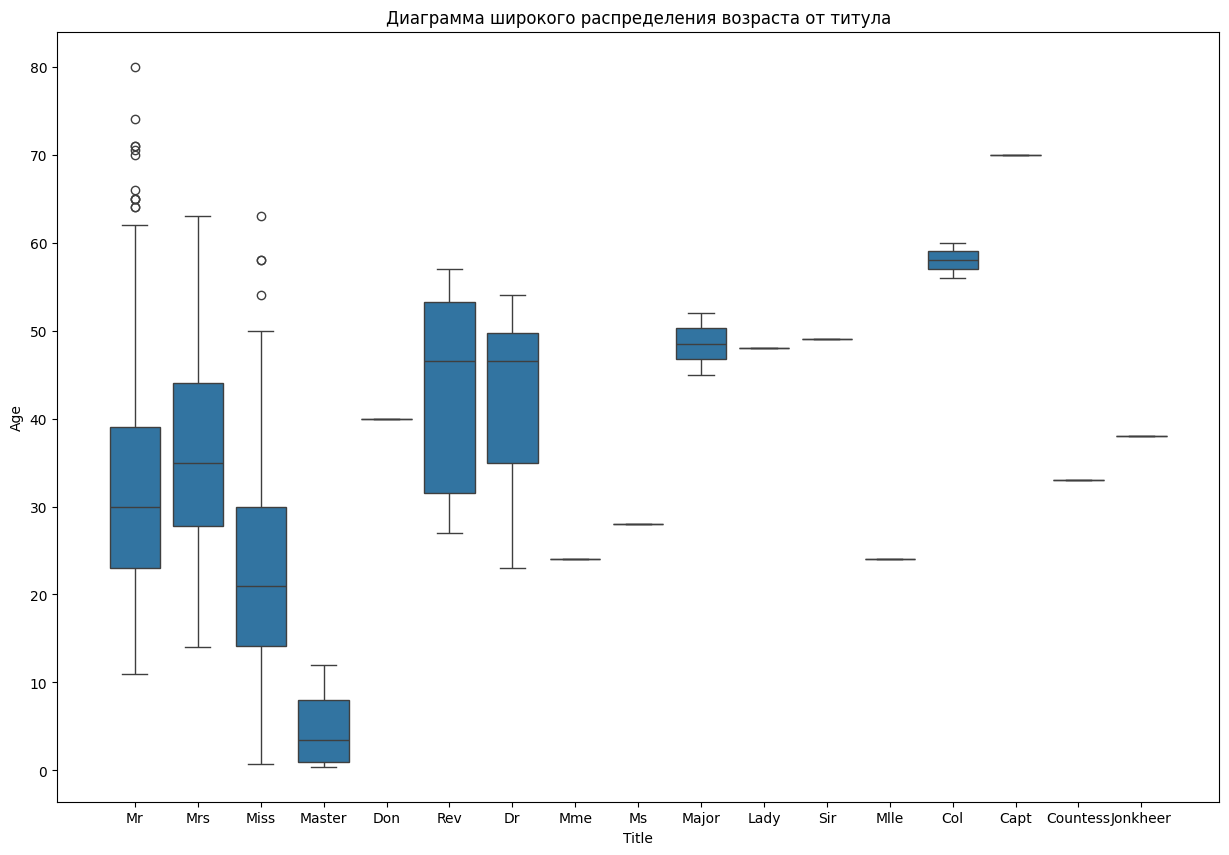

In [110]:
plt.figure(figsize=(15, 10))
sns.boxplot(data=df_train, x='Title', y='Age')
plt.title("Диаграмма широкого распределения возраста от титула")
plt.plot()

In [111]:
df2 = df_train[['Age', 'Title']].groupby(df_train['Title']).median(numeric_only=True)
df_titles = pd.merge(df_titles, df2, how='inner', on='Title')
df_titles

,Title,Count,NumberNan,Age
0,Mr,517,119,30.0
1,Miss,182,36,21.0
2,Mrs,125,17,35.0
3,Master,40,4,3.5
4,Dr,7,1,46.5
5,Rev,6,0,46.5
6,Mlle,2,0,24.0
7,Major,2,0,48.5
8,Col,2,0,58.0
9,Capt,1,0,70.0


In [112]:
df_train['Age'] = df_train['Age'].fillna(df_train.groupby('Title')['Age'].transform('median'))

In [113]:
df_train

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Mr
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Mrs
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Miss
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Mrs
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Mr
...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,Rev
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,Miss
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,21.0,1,2,W./C. 6607,23.4500,NaN,S,Miss
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,Mr


Cabin

In [114]:
df_train['Cabin'].isna().value_counts()

Cabin
True     687
False    204
Name: count, dtype: int64

In [115]:
df_train.groupby(df_train['Cabin'].isna())['Survived'].value_counts(normalize=True)

Cabin  Survived
False  1           0.666667
       0           0.333333
True   0           0.700146
       1           0.299854
Name: proportion, dtype: float64

In [116]:
df_train['Cabin'].unique()

array([nan, 'C85', 'C123', 'E46', 'G6', 'C103', 'D56', 'A6',
       'C23 C25 C27', 'B78', 'D33', 'B30', 'C52', 'B28', 'C83', 'F33',
       'F G73', 'E31', 'A5', 'D10 D12', 'D26', 'C110', 'B58 B60', 'E101',
       'F E69', 'D47', 'B86', 'F2', 'C2', 'E33', 'B19', 'A7', 'C49', 'F4',
       'A32', 'B4', 'B80', 'A31', 'D36', 'D15', 'C93', 'C78', 'D35',
       'C87', 'B77', 'E67', 'B94', 'C125', 'C99', 'C118', 'D7', 'A19',
       'B49', 'D', 'C22 C26', 'C106', 'C65', 'E36', 'C54',
       'B57 B59 B63 B66', 'C7', 'E34', 'C32', 'B18', 'C124', 'C91', 'E40',
       'T', 'C128', 'D37', 'B35', 'E50', 'C82', 'B96 B98', 'E10', 'E44',
       'A34', 'C104', 'C111', 'C92', 'E38', 'D21', 'E12', 'E63', 'A14',
       'B37', 'C30', 'D20', 'B79', 'E25', 'D46', 'B73', 'C95', 'B38',
       'B39', 'B22', 'C86', 'C70', 'A16', 'C101', 'C68', 'A10', 'E68',
       'B41', 'A20', 'D19', 'D50', 'D9', 'A23', 'B50', 'A26', 'D48',
       'E58', 'C126', 'B71', 'B51 B53 B55', 'D49', 'B5', 'B20', 'F G63',
       'C62 C64',

In [117]:
df_cabin = df_train.copy()
df_cabin['Cabin'] = df_cabin['Cabin'].fillna('N').str.extract('([A-Z])', expand=False)
df_cabin['Cabin'].value_counts()

Cabin
N    687
C     59
B     47
D     33
E     32
A     15
F     13
G      4
T      1
Name: count, dtype: int64

In [118]:
df_cabin.groupby(df_cabin['Cabin'])['Survived'].value_counts()

Cabin  Survived
A      0             8
       1             7
B      1            35
       0            12
C      1            35
       0            24
D      1            25
       0             8
E      1            24
       0             8
F      1             8
       0             5
G      0             2
       1             2
N      0           481
       1           206
T      0             1
Name: count, dtype: int64

In [119]:
df_train['HaveCabin'] = np.where(df_train['Cabin'].isna(), 0, 1)

In [120]:
df_train['Sex'].unique()

array(['male', 'female'], dtype=object)

In [121]:
df_train_digit = df_train[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp',
       'Parch', 'Fare', 'Embarked', 'HaveCabin']].copy()

df_train_digit['Embarked'] = df_train_digit['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})
df_train_digit['Sex'] = df_train_digit['Sex'].map({'male': 0, 'female': 1})

df_train_digit

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,HaveCabin
0,0,3,0,22.0,1,0,7.2500,0,0
1,1,1,1,38.0,1,0,71.2833,1,1
2,1,3,1,26.0,0,0,7.9250,0,0
3,1,1,1,35.0,1,0,53.1000,0,1
4,0,3,0,35.0,0,0,8.0500,0,0
...,...,...,...,...,...,...,...,...,...
886,0,2,0,27.0,0,0,13.0000,0,0
887,1,1,1,19.0,0,0,30.0000,0,1
888,0,3,1,21.0,1,2,23.4500,0,0
889,1,1,0,26.0,0,0,30.0000,1,1


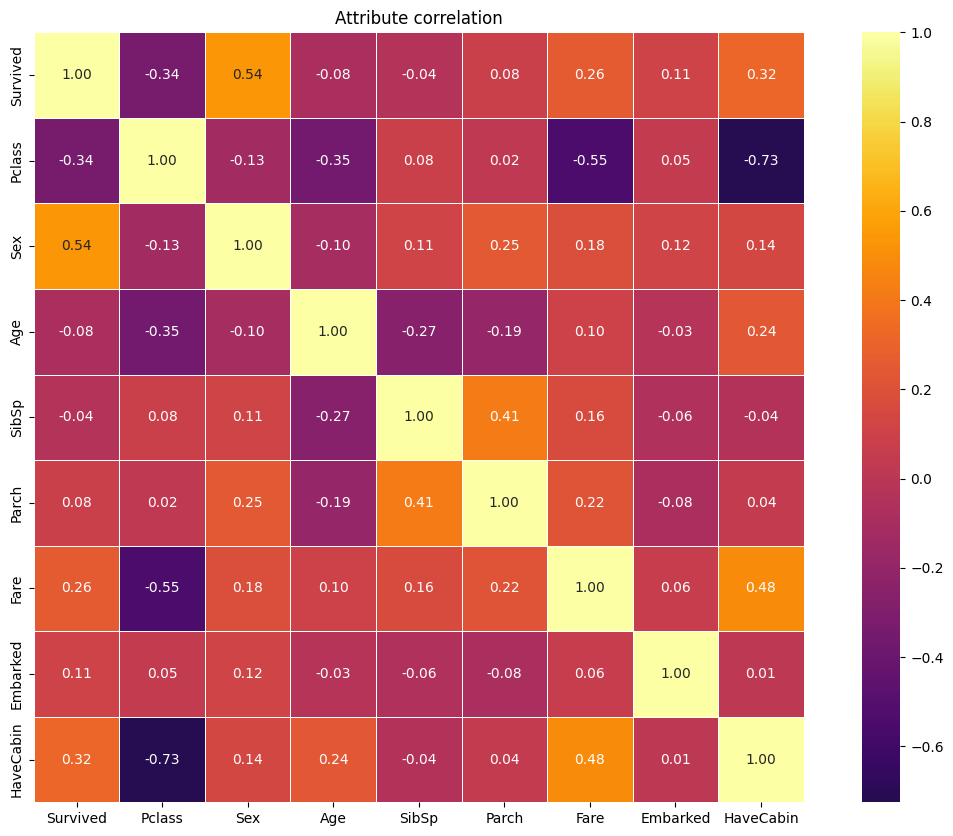

In [122]:
corr_matrix = df_train_digit.corr()

plt.figure(figsize=(15, 10))

sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='inferno', center=0,
            square=True, linewidths=.5)
plt.title('Attribute correlation')
plt.show()

Разделим датасет на два варианта, со всем стобцами или с самыми важными (где коэффициент корреляции больше 0.1)

In [123]:
df_train_digit_all = df_train_digit.copy()

df_train_digit_small = df_train_digit[['Survived', 'Pclass', 'Sex', 'Fare', 'Embarked', 'HaveCabin']]

Повторим то же самое и с df_test

In [124]:
df_test_digit = df_test.copy()
df_test_digit

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...
413,1305,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


In [125]:
print(pd.concat([df_test_digit.isna().sum(), df_test_digit.notna().sum()], axis=1))

               0    1
PassengerId    0  418
Pclass         0  418
Name           0  418
Sex            0  418
Age           86  332
SibSp          0  418
Parch          0  418
Ticket         0  418
Fare           1  417
Cabin        327   91
Embarked       0  418


In [126]:
df_test_digit['Title'] = df_test_digit['Name'].str.extract(' ([a-zA-Z]+)\.')
df_test_digit['Age'] = df_test_digit['Age'].fillna(df_train.groupby('Title')['Age'].transform('median'))
df_test_digit['Fare'] = df_test_digit['Fare'].fillna(df_train['Fare'].median())
df_test_digit['HaveCabin'] = np.where(df_test_digit['Cabin'].isna(), 0, 1)
df_test_digit['Embarked'] = df_test_digit['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})
df_test_digit['Sex'] = df_test_digit['Sex'].map({'male': 0, 'female': 1})
df_test_digit = pd.merge(df_gender, df_test_digit, on='PassengerId')

In [127]:
df_test_digit

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,HaveCabin
0,892,0,3,"Kelly, Mr. James",0,34.5,0,0,330911,7.8292,NaN,2,Mr,0
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",1,47.0,1,0,363272,7.0000,NaN,0,Mrs,0
2,894,0,2,"Myles, Mr. Thomas Francis",0,62.0,0,0,240276,9.6875,NaN,2,Mr,0
3,895,0,3,"Wirz, Mr. Albert",0,27.0,0,0,315154,8.6625,NaN,0,Mr,0
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",1,22.0,1,1,3101298,12.2875,NaN,0,Mrs,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
413,1305,0,3,"Spector, Mr. Woolf",0,30.0,0,0,A.5. 3236,8.0500,NaN,0,Mr,0
414,1306,1,1,"Oliva y Ocana, Dona. Fermina",1,39.0,0,0,PC 17758,108.9000,C105,1,Dona,1
415,1307,0,3,"Saether, Mr. Simon Sivertsen",0,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,0,Mr,0
416,1308,0,3,"Ware, Mr. Frederick",0,35.0,0,0,359309,8.0500,NaN,0,Mr,0


In [128]:
print(pd.concat([df_test_digit.isna().sum(), df_test_digit.notna().sum()], axis=1))

               0    1
PassengerId    0  418
Survived       0  418
Pclass         0  418
Name           0  418
Sex            0  418
Age            0  418
SibSp          0  418
Parch          0  418
Ticket         0  418
Fare           0  418
Cabin        327   91
Embarked       0  418
Title          0  418
HaveCabin      0  418


In [129]:
df_test_digit_all = df_test_digit[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch',
                                   'Fare', 'Embarked', 'HaveCabin']].copy()

df_test_digit_small = df_test_digit[['Survived', 'Pclass', 'Sex', 'Fare', 'Embarked', 'HaveCabin']].copy()

In [130]:
df_train_digit_all.shape[0]

891

In [137]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils import resample
from sklearn.metrics import *


estimators = [('Tree', DecisionTreeClassifier()),
              ('Tree 5 depth', DecisionTreeClassifier(max_depth=5)),
              ('Bagging(Tree)', BaggingClassifier(DecisionTreeClassifier(), n_estimators=10, max_samples=1.)),
              ('Bagging(Tree 5 depth)', BaggingClassifier(DecisionTreeClassifier(max_depth=5), n_estimators=10, max_samples=1.))]

n_estimators = len(estimators)
n_repeat = 50
features_all = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'Embarked', 'HaveCabin']
features_small = ['Pclass', 'Sex', 'Fare', 'Embarked', 'HaveCabin']

def get_all(model_name, y_pred, y_test):
    print(f'Оценка {model_name}')
    print(f'Accuracy: {accuracy_score(y_test, y_pred):.2f}')
    print(f'Precision: {precision_score(y_test, y_pred):.2f}')
    print(f'Recall: {recall_score(y_test, y_pred):.2f}')
    print(f'f1: {f1_score(y_test, y_pred):.2f}')
    cm = confusion_matrix(y_test, y_pred)
    print("Confusion Matrix (Матрица ошибок):")
    print(f'{cm[0]} T-')
    print(f'{cm[1]} T+')
    print(' P-  P+')


def comparison(train, test, features, target, estimators):
    y_train, X_train = train[target].values , train[features].values
    y_test, X_test = test[target].values , test[features].values
    results = {}
    end_estimators = {}
    
    for n, (name, estimator) in enumerate(estimators):
        y_predict = np.zeros((df_test.shape[0], n_repeat))

        for i in range(n_repeat):
            X_sample, y_sample = resample(X_train, y_train, replace=True, random_state=i)
            estimator.fit(X_sample, y_sample)
            y_predict[:, i] = estimator.predict(X_test)
        
        y_predict_mean = np.mean(y_predict, axis=1)
        y_final = np.where(y_predict_mean >= 0.7, 1, 0)

        y_error = 1 - np.mean(y_final == y_test)
        y_var = np.var(y_test)
        print('{0:13.21}:\n{1:.3f} (error)\n{2:.3f} (var)'.format(name, y_error, y_var))
        results[name] = y_final
        end_estimators[name] = estimator
        get_all(name, y_final, y_test)
    return [results, end_estimators]

result = {}
end_estimators = {}
result['all'], end_estimators['all'] = comparison(df_train_digit_all, df_test_digit_all, features_all, 'Survived', estimators)

result['small'], end_estimators['all'] = comparison(df_train_digit_small, df_test_digit_small, features_small, 'Survived', estimators)

Tree         :
0.187 (error)
0.231 (var)
Оценка Tree
Accuracy: 0.81
Precision: 0.82
Recall: 0.62
f1: 0.71
Confusion Matrix (Матрица ошибок):
[245  21] T-
[57 95] T+
 P-  P+
Tree 5 depth :
0.134 (error)
0.231 (var)
Оценка Tree 5 depth
Accuracy: 0.87
Precision: 0.94
Recall: 0.67
f1: 0.78
Confusion Matrix (Матрица ошибок):
[260   6] T-
[ 50 102] T+
 P-  P+
Bagging(Tree):
0.151 (error)
0.231 (var)
Оценка Bagging(Tree)
Accuracy: 0.85
Precision: 0.88
Recall: 0.68
f1: 0.77
Confusion Matrix (Матрица ошибок):
[252  14] T-
[ 49 103] T+
 P-  P+
Bagging(Tree 5 depth):
0.115 (error)
0.231 (var)
Оценка Bagging(Tree 5 depth)
Accuracy: 0.89
Precision: 0.94
Recall: 0.73
f1: 0.82
Confusion Matrix (Матрица ошибок):
[259   7] T-
[ 41 111] T+
 P-  P+
Tree         :
0.136 (error)
0.231 (var)
Оценка Tree
Accuracy: 0.86
Precision: 0.88
Recall: 0.72
f1: 0.79
Confusion Matrix (Матрица ошибок):
[251  15] T-
[ 42 110] T+
 P-  P+
Tree 5 depth :
0.093 (error)
0.231 (var)
Оценка Tree 5 depth
Accuracy: 0.91
Precision

Отлично, с меньшими параметрами даже лучше получается, а если объединим показатели "семейности"?

In [138]:
df_agregate_digit = df_train_digit_all.copy()

df_test_agregate = df_test_digit_all.copy()

In [139]:
df_agregate_digit['Family'] = df_agregate_digit['Parch'] + df_agregate_digit['SibSp']

df_agregate_digit = df_agregate_digit.drop(axis=1, columns=['Parch', 'SibSp'])

df_test_agregate['Family'] = df_test_agregate['Parch'] + df_test_agregate['SibSp']

df_test_agregate = df_test_agregate.drop(axis=1, columns=['Parch', 'SibSp'])

In [140]:
result['agr'], end_estimators['agr'] = comparison(df_agregate_digit, df_test_agregate, ['Pclass', 'Sex', 'Age', 'Fare', 'Embarked', 'HaveCabin',
       'Family'], 'Survived', estimators)


Tree         :
0.184 (error)
0.231 (var)
Оценка Tree
Accuracy: 0.82
Precision: 0.83
Recall: 0.62
f1: 0.71
Confusion Matrix (Матрица ошибок):
[246  20] T-
[57 95] T+
 P-  P+
Tree 5 depth :
0.134 (error)
0.231 (var)
Оценка Tree 5 depth
Accuracy: 0.87
Precision: 0.94
Recall: 0.67
f1: 0.78
Confusion Matrix (Матрица ошибок):
[260   6] T-
[ 50 102] T+
 P-  P+
Bagging(Tree):
0.163 (error)
0.231 (var)
Оценка Bagging(Tree)
Accuracy: 0.84
Precision: 0.86
Recall: 0.66
f1: 0.75
Confusion Matrix (Матрица ошибок):
[249  17] T-
[ 51 101] T+
 P-  P+
Bagging(Tree 5 depth):
0.124 (error)
0.231 (var)
Оценка Bagging(Tree 5 depth)
Accuracy: 0.88
Precision: 0.94
Recall: 0.70
f1: 0.80
Confusion Matrix (Матрица ошибок):
[259   7] T-
[ 45 107] T+
 P-  P+


In [141]:
def visualize(predict_data, test_data, title='Vizualizing'):
    fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(15, 10))

    ax_flat = axes.flatten()

    plt.title(title)

    metrics = {m: {} for m in ['accuracy', 'precision', 'recall', 'f1']}

    for key, value in predict_data.items():
        metrics['accuracy'][key] = accuracy_score(test_data, value)
        metrics['precision'][key] = precision_score(test_data, value)
        metrics['recall'][key] = recall_score(test_data, value)
        metrics['f1'][key] = f1_score(test_data, value)

    print(metrics)
    for (metric_name, models_dict), ax in zip(metrics.items(), ax_flat):
        model_names = list(models_dict.keys())
        scores = list(models_dict.values())
        print(model_names, scores)
        sns.barplot(x=model_names, y=scores, ax=ax)
        
        ax.set_title(f'{metric_name} score')
        ax.set_ylim([0, 1])
        for container in ax.containers:
            ax.bar_label(container, label_type='center', color='white')
        ax.grid(True, alpha=0.5, color='black')
        

{'accuracy': {'Tree': 0.8157894736842105, 'Tree 5 depth': 0.8660287081339713, 'Bagging(Tree)': 0.8373205741626795, 'Bagging(Tree 5 depth)': 0.8755980861244019}, 'precision': {'Tree': 0.8260869565217391, 'Tree 5 depth': 0.9444444444444444, 'Bagging(Tree)': 0.8559322033898306, 'Bagging(Tree 5 depth)': 0.9385964912280702}, 'recall': {'Tree': 0.625, 'Tree 5 depth': 0.6710526315789473, 'Bagging(Tree)': 0.6644736842105263, 'Bagging(Tree 5 depth)': 0.7039473684210527}, 'f1': {'Tree': 0.7116104868913857, 'Tree 5 depth': 0.7846153846153846, 'Bagging(Tree)': 0.7481481481481481, 'Bagging(Tree 5 depth)': 0.8045112781954887}}
['Tree', 'Tree 5 depth', 'Bagging(Tree)', 'Bagging(Tree 5 depth)'] [0.8157894736842105, 0.8660287081339713, 0.8373205741626795, 0.8755980861244019]
['Tree', 'Tree 5 depth', 'Bagging(Tree)', 'Bagging(Tree 5 depth)'] [0.8260869565217391, 0.9444444444444444, 0.8559322033898306, 0.9385964912280702]
['Tree', 'Tree 5 depth', 'Bagging(Tree)', 'Bagging(Tree 5 depth)'] [0.625, 0.671052

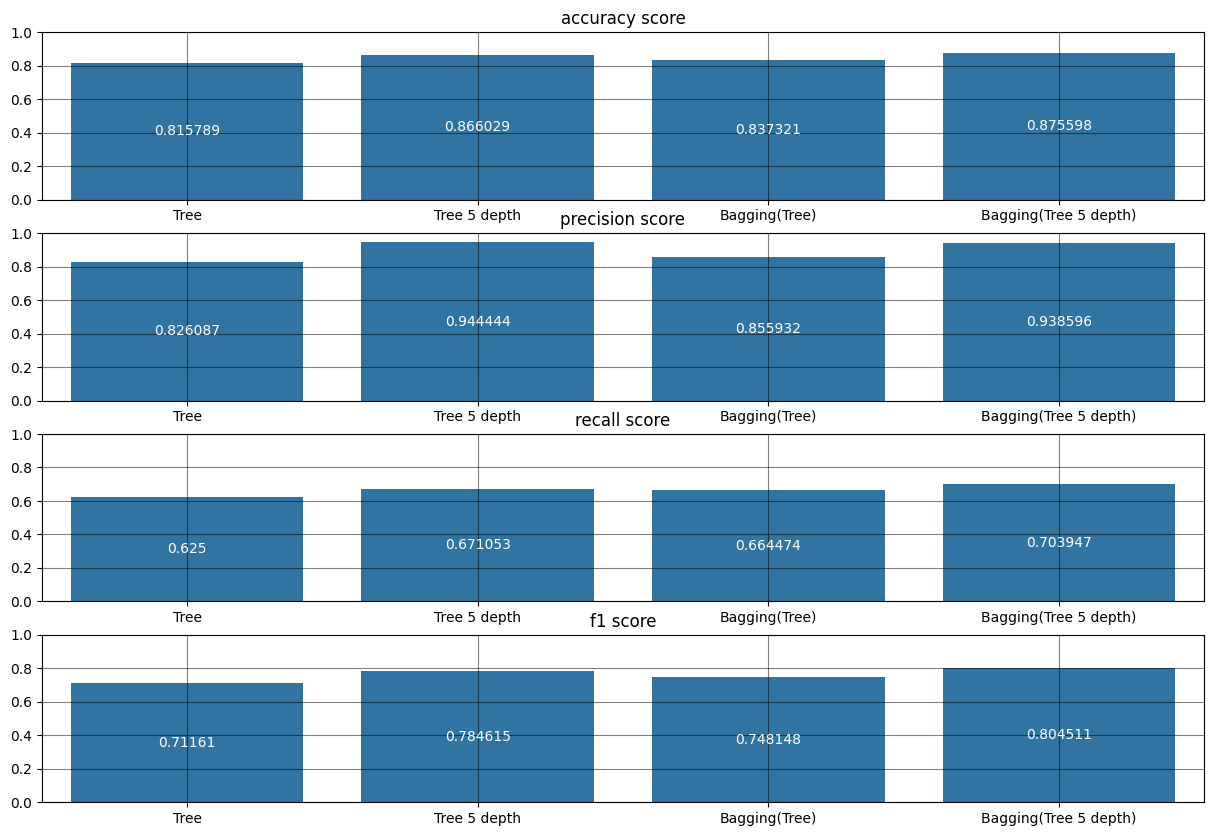

In [142]:
data_for_visualize = result['agr']
visualize(data_for_visualize, df_test_digit['Survived'], title='Vizualize with agregation')

{'accuracy': {'Tree': 0.8636363636363636, 'Tree 5 depth': 0.9066985645933014, 'Bagging(Tree)': 0.8851674641148325, 'Bagging(Tree 5 depth)': 0.9043062200956937}, 'precision': {'Tree': 0.88, 'Tree 5 depth': 1.0, 'Bagging(Tree)': 0.8939393939393939, 'Bagging(Tree 5 depth)': 1.0}, 'recall': {'Tree': 0.7236842105263158, 'Tree 5 depth': 0.743421052631579, 'Bagging(Tree)': 0.7763157894736842, 'Bagging(Tree 5 depth)': 0.7368421052631579}, 'f1': {'Tree': 0.7942238267148014, 'Tree 5 depth': 0.8528301886792453, 'Bagging(Tree)': 0.8309859154929577, 'Bagging(Tree 5 depth)': 0.8484848484848485}}
['Tree', 'Tree 5 depth', 'Bagging(Tree)', 'Bagging(Tree 5 depth)'] [0.8636363636363636, 0.9066985645933014, 0.8851674641148325, 0.9043062200956937]
['Tree', 'Tree 5 depth', 'Bagging(Tree)', 'Bagging(Tree 5 depth)'] [0.88, 1.0, 0.8939393939393939, 1.0]
['Tree', 'Tree 5 depth', 'Bagging(Tree)', 'Bagging(Tree 5 depth)'] [0.7236842105263158, 0.743421052631579, 0.7763157894736842, 0.7368421052631579]
['Tree', 'Tr

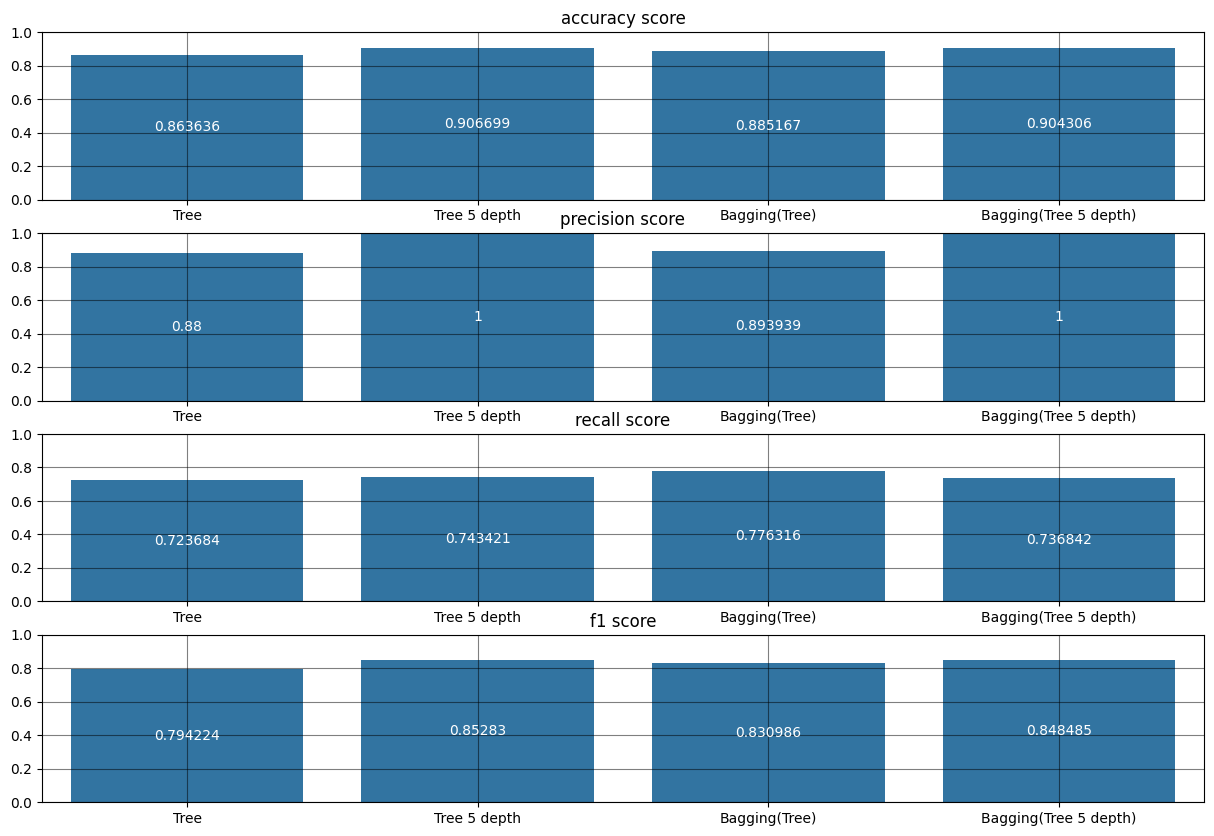

In [143]:
data_for_visualize = result['small']
visualize(data_for_visualize, df_test_digit['Survived'])

XGBoost

In [144]:
df_train_categorial = df_train.copy()
df_train_categorial

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,HaveCabin
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Mr,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Mrs,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Miss,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Mrs,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Mr,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,Rev,0
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,Miss,1
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,21.0,1,2,W./C. 6607,23.4500,NaN,S,Miss,0
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,Mr,1


In [145]:
df_train_categorial = df_train_categorial.drop(axis=1, columns=['Name', 'Ticket', 'HaveCabin', 'PassengerId', 'Title'])
df_train_categorial['Cabin'] = df_train_categorial['Cabin'].fillna('N')
df_train_categorial['Cabin'] = df_train_categorial['Cabin'].str.extract('([A-Z])')
df_train_categorial

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,3,male,22.0,1,0,7.2500,N,S
1,1,1,female,38.0,1,0,71.2833,C,C
2,1,3,female,26.0,0,0,7.9250,N,S
3,1,1,female,35.0,1,0,53.1000,C,S
4,0,3,male,35.0,0,0,8.0500,N,S
...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,N,S
887,1,1,female,19.0,0,0,30.0000,B,S
888,0,3,female,21.0,1,2,23.4500,N,S
889,1,1,male,26.0,0,0,30.0000,C,C


In [146]:
df_test_categorial = df_test_digit[['Survived', 'Pclass', 'Sex', 'Age', 'SibSp',
       'Parch', 'Fare', 'Cabin', 'Embarked']].copy()
df_test_categorial['Cabin'] = df_test_categorial['Cabin'].fillna('N')
df_test_categorial['Cabin'] = df_test_categorial['Cabin'].str.extract('([A-Z])')
df_test_categorial['Sex'] = np.where(df_test_categorial['Sex'] == 0, 'male', 'female')
df_test_categorial['Embarked'] = df_test_categorial['Embarked'].map({0: 'S', 1: 'C', 2: 'Q'})
df_test_categorial

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,3,male,34.5,0,0,7.8292,N,Q
1,1,3,female,47.0,1,0,7.0000,N,S
2,0,2,male,62.0,0,0,9.6875,N,Q
3,0,3,male,27.0,0,0,8.6625,N,S
4,1,3,female,22.0,1,1,12.2875,N,S
...,...,...,...,...,...,...,...,...,...
413,0,3,male,30.0,0,0,8.0500,N,S
414,1,1,female,39.0,0,0,108.9000,C,C
415,0,3,male,38.5,0,0,7.2500,N,S
416,0,3,male,35.0,0,0,8.0500,N,S


Оценка XGBClassifier
Accuracy: 0.86
Precision: 0.80
Recall: 0.81
f1: 0.80
Confusion Matrix (Матрица ошибок):
[235  31] T-
[ 29 123] T+
 P-  P+
{'accuracy': {'Tree': 0.8636363636363636, 'Tree 5 depth': 0.9066985645933014, 'Bagging(Tree)': 0.8851674641148325, 'Bagging(Tree 5 depth)': 0.9043062200956937, 'XGB': 0.8564593301435407}, 'precision': {'Tree': 0.88, 'Tree 5 depth': 1.0, 'Bagging(Tree)': 0.8939393939393939, 'Bagging(Tree 5 depth)': 1.0, 'XGB': 0.7987012987012987}, 'recall': {'Tree': 0.7236842105263158, 'Tree 5 depth': 0.743421052631579, 'Bagging(Tree)': 0.7763157894736842, 'Bagging(Tree 5 depth)': 0.7368421052631579, 'XGB': 0.8092105263157895}, 'f1': {'Tree': 0.7942238267148014, 'Tree 5 depth': 0.8528301886792453, 'Bagging(Tree)': 0.8309859154929577, 'Bagging(Tree 5 depth)': 0.8484848484848485, 'XGB': 0.803921568627451}}
['Tree', 'Tree 5 depth', 'Bagging(Tree)', 'Bagging(Tree 5 depth)', 'XGB'] [0.8636363636363636, 0.9066985645933014, 0.8851674641148325, 0.9043062200956937, 0.8564

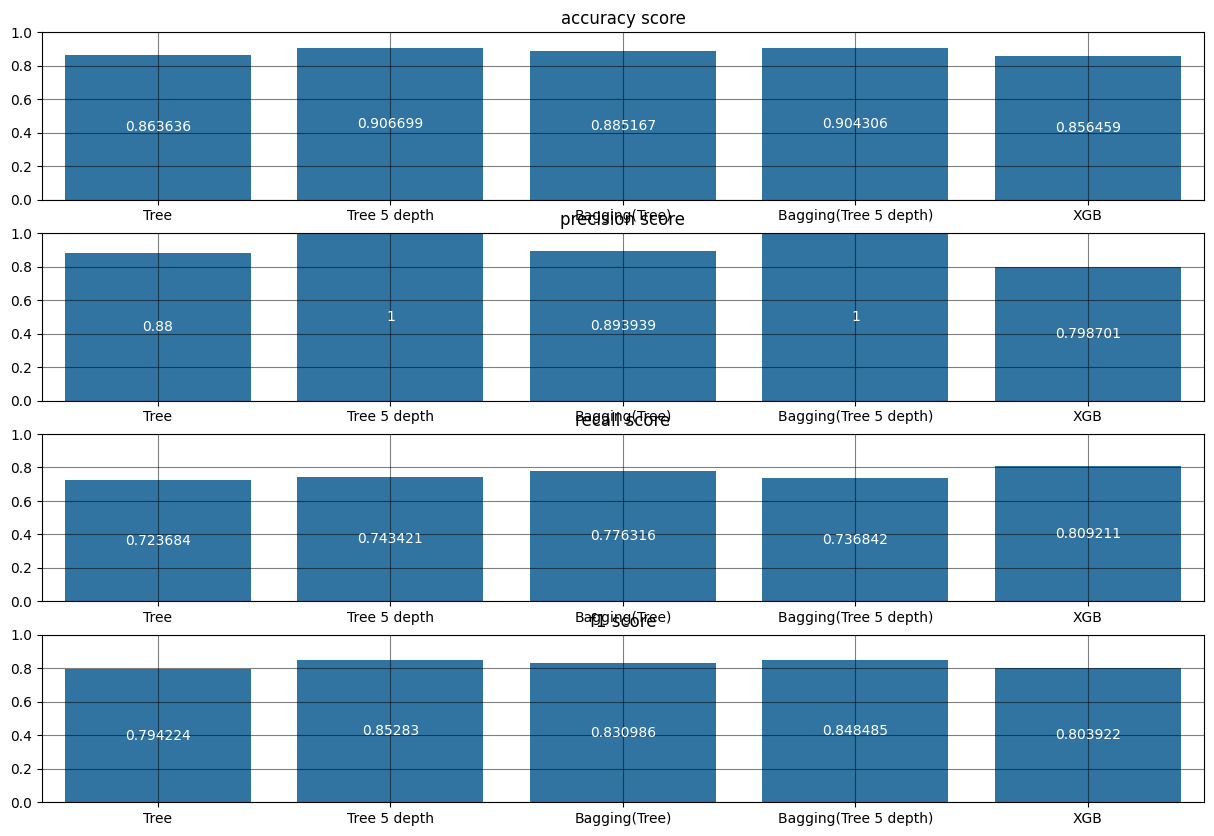

In [147]:
import xgboost

# X_train, y_train = df_train_categorial[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Cabin',
#        'Embarked']], df_train_categorial['Survived']
# X_test, y_test = df_test_categorial[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Cabin',
#        'Embarked']], df_test_categorial['Survived']

X_train, y_train = df_train_digit_small[['Pclass', 'Sex', 'Fare', 'HaveCabin',
       'Embarked']], df_train_digit_small['Survived']
X_test, y_test = df_test_digit_small[['Pclass', 'Sex', 'Fare', 'HaveCabin',
       'Embarked']], df_test_digit_small['Survived']

model = xgboost.XGBClassifier(enable_categorical=True, tree_method='hist')
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
get_all('XGBClassifier', y_pred=y_pred, y_test=y_test)
result['small']['XGB'] = y_pred
visualize(result['small'], test_data=y_test)

Catboost

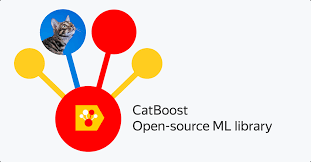
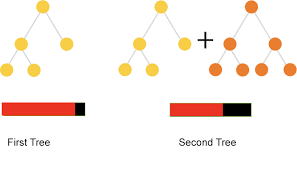

In [148]:
from catboost import Pool, CatBoostClassifier


model = CatBoostClassifier(iterations=10,
                           learning_rate=1,
                           depth=5,
                           loss_function='MultiClass')

train_data = df_train_categorial[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Cabin',
       'Embarked']]
test_data = df_test_categorial[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Cabin',
       'Embarked']]

train_label = df_train_categorial['Survived']
test_label = df_test_categorial['Survived']

cat_features = [1, 6, 7]

train_dataset = Pool(data=train_data,
                     label=train_label,
                     cat_features=cat_features)

test_dataset = Pool(data=test_data,
                     label=test_label,
                     cat_features=cat_features)

model.fit(train_dataset)
y_pred = model.predict(test_dataset)
get_all('Catboost', y_pred, test_label)

0:	learn: 0.5148369	total: 10.1ms	remaining: 90.9ms
1:	learn: 0.4392273	total: 38.2ms	remaining: 153ms
2:	learn: 0.4151411	total: 59.7ms	remaining: 139ms
3:	learn: 0.3914263	total: 79.9ms	remaining: 120ms
4:	learn: 0.3853437	total: 101ms	remaining: 101ms
5:	learn: 0.3827454	total: 125ms	remaining: 83.3ms
6:	learn: 0.3768235	total: 143ms	remaining: 61.4ms
7:	learn: 0.3742764	total: 162ms	remaining: 40.4ms
8:	learn: 0.3613169	total: 180ms	remaining: 20ms
9:	learn: 0.3545057	total: 201ms	remaining: 0us
Оценка Catboost
Accuracy: 0.91
Precision: 0.87
Recall: 0.88
f1: 0.87
Confusion Matrix (Матрица ошибок):
[246  20] T-
[ 19 133] T+
 P-  P+


Займёмся P-tuning-ом параметров

In [50]:
model = CatBoostClassifier(loss_function ='MultiClass', task_type='GPU')

grid = {'iterations': [100, 150, 200],
        'learning_rate': [0.03, .1],
        'depth': [2, 4, 6, 8],
        'l2_leaf_reg': [.2, .5, 1, 3]}

model.grid_search(grid, train_dataset)

0:	learn: 0.6807179	test: 0.6813185	best: 0.6813185 (0)	total: 65.9ms	remaining: 6.53s
1:	learn: 0.6690150	test: 0.6701969	best: 0.6701969 (1)	total: 69.3ms	remaining: 3.39s
2:	learn: 0.6579845	test: 0.6597299	best: 0.6597299 (2)	total: 74.1ms	remaining: 2.4s
3:	learn: 0.6475776	test: 0.6498703	best: 0.6498703 (3)	total: 79.3ms	remaining: 1.9s
4:	learn: 0.6377502	test: 0.6405756	best: 0.6405756 (4)	total: 83.8ms	remaining: 1.59s
5:	learn: 0.6284625	test: 0.6318070	best: 0.6318070 (5)	total: 87.6ms	remaining: 1.37s
6:	learn: 0.6196783	test: 0.6235294	best: 0.6235294 (6)	total: 91.4ms	remaining: 1.21s
7:	learn: 0.6113646	test: 0.6157108	best: 0.6157108 (7)	total: 95.5ms	remaining: 1.1s
8:	learn: 0.6034911	test: 0.6083216	best: 0.6083216 (8)	total: 99.3ms	remaining: 1s
9:	learn: 0.5960301	test: 0.6013348	best: 0.6013348 (9)	total: 103ms	remaining: 923ms
10:	learn: 0.5889564	test: 0.5947259	best: 0.5947259 (10)	total: 106ms	remaining: 857ms
11:	learn: 0.5822463	test: 0.5884718	best: 0.5884

{'params': {'depth': 4,
  'learning_rate': 0.1,
  'l2_leaf_reg': 3,
  'iterations': 100},
 'cv_results': defaultdict(list,
             {'iterations': [0,
               1,
               2,
               3,
               4,
               5,
               6,
               7,
               8,
               9,
               10,
               11,
               12,
               13,
               14,
               15,
               16,
               17,
               18,
               19,
               20,
               21,
               22,
               23,
               24,
               25,
               26,
               27,
               28,
               29,
               30,
               31,
               32,
               33,
               34,
               35,
               36,
               37,
               38,
               39,
               40,
               41,
               42,
               43,
               44,
               45,

In [149]:
y_pred = model.predict(test_dataset)
print('Testing performance')
print('Accuracy: {:.2f}'.format(accuracy_score(test_label, y_pred)))
print('PMSE: {:.2f}'.format(np.sqrt(mean_squared_error(y_test, y_pred))))
print('R2: {:.2f}'.format(r2_score(y_test, y_pred)))

Testing performance
Accuracy: 0.91
PMSE: 0.31
R2: 0.60


<Axes: >

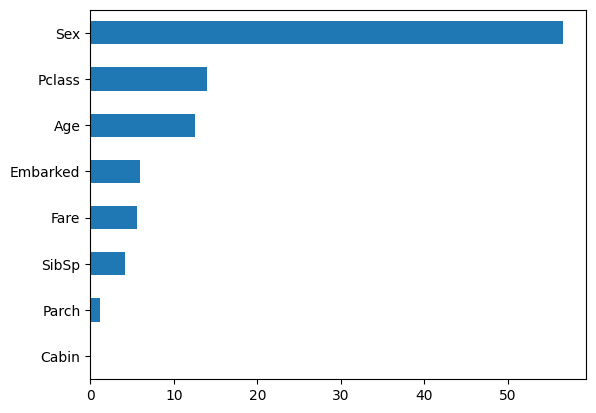

In [150]:
sorted_feature_importance = model.feature_importances_.argsort()
(pd.Series(model.feature_importances_, index=test_data.columns).sort_values().plot(kind='barh'))